# Dataset 5 

In [1]:
# Imports & Dataset Loading
import os
import pandas as pd
import numpy as np

# Read Dataset 5 from Datasets folder
if os.path.exists("../Datasets/Dataset5.csv"):
    df = pd.read_csv("../Datasets/Dataset5.csv")
elif os.path.exists("../Datasets/Final_Job_Postings_Dataset.csv"):
    df = pd.read_csv("../Datasets/Final_Job_Postings_Dataset.csv")
    df.to_csv("../Datasets/Dataset5.csv", index=False)
else:
    df = pd.read_csv("Final_Job_Postings_Dataset.csv")
    df.to_csv("../Datasets/Dataset5.csv", index=False)

In [2]:
# Exploratory Data Analysis (EDA)

# Display first 5 rows
df.head()

,Job Title,Job Description,Is Fake
0,Marketing Intern,"Food52, a fast-growing, James Beard Award-winn...",Human-Written
1,Customer Service - Cloud Video Production,Organised - Focused - Vibrant - Awesome!Do you...,Human-Written
2,Commissioning Machinery Assistant (CMA),"Our client, located in Houston, is actively se...",Human-Written
3,Account Executive - Washington DC,THE COMPANY: ESRI – Environmental Systems Rese...,Human-Written
4,Bill Review Manager,JOB TITLE: Itemization Review ManagerLOCATION:...,Human-Written


In [3]:
# Dataset Size & Dimensions

# Check total rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (17889, 3)


In [4]:
# Column Names

# Check all available features
print("Columns in Dataset 5:\n", df.columns.tolist())

Columns in Dataset 5:
 ['Job Title', 'Job Description', 'Is Fake']


In [5]:
# Data Information & Types

# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17889 entries, 0 to 17888
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Job Title        17889 non-null  object
 1   Job Description  17889 non-null  object
 2   Is Fake          17889 non-null  object
dtypes: object(3)
memory usage: 419.4+ KB


In [6]:
# Check Missing Values

# Count missing values per column
df.isnull().sum()

Job Title          0
Job Description    0
Is Fake            0
dtype: int64

In [7]:
# Target Class Distribution

# Check class balance
print("Target Distribution:")
print(df["Is Fake"].value_counts(dropna=False))

# Human-Written = Legitimate jobs (0)
# Fake / AI-Generated = Fraudulent jobs (1)

Target Distribution:
Is Fake
Human-Written    17014
Fake               865
AI-Generated        10
Name: count, dtype: int64


## Data Cleaning & Text Feature Combination

In [8]:
# Cleaning Pipeline

# 1. Make a working copy
df_clean = df.copy()

# 2. Encode target: 'Human-Written' -> 0 (Real), 'Fake' / 'AI-Generated' -> 1 (Fake)
df_clean['fraudulent'] = df_clean['Is Fake'].apply(lambda x: 0 if str(x).strip().lower() == 'human-written' else 1).astype(int)

# 3. Combine text features into a single 'text' column
df_clean['text'] = (
    df_clean['Job Title'].fillna('').astype(str) + " " +
    df_clean['Job Description'].fillna('').astype(str)
)

# 4. Preview combined text
df_clean[['text', 'fraudulent']].head()

,text,fraudulent
0,"Marketing Intern Food52, a fast-growing, James...",0
1,Customer Service - Cloud Video Production Orga...,0
2,Commissioning Machinery Assistant (CMA) Our cl...,0
3,Account Executive - Washington DC THE COMPANY:...,0
4,Bill Review Manager JOB TITLE: Itemization Rev...,0


In [9]:
# Save Cleaned Dataset as CSV

# Ensure data directory exists and save
os.makedirs("../data/processed", exist_ok=True)
df_clean.to_csv("../data/processed/cleaned_fake_jobs_dataset5.csv", index=False)
print("✅ Cleaned Dataset 5 saved to data/processed/cleaned_fake_jobs_dataset5.csv")

✅ Cleaned Dataset 5 saved to data/processed/cleaned_fake_jobs_dataset5.csv


## Natural Language Processing (NLP) & Text Preprocessing

In [10]:
# NLTK Setup & Preprocessing Function

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)     # Remove punctuation
    tokens = word_tokenize(text)            # Tokenization
    tokens = [word for word in tokens if word not in stop_words]  # Remove stopwords
    tokens = [lemmatizer.lemmatize(word) for word in tokens]      # Lemmatization
    return " ".join(tokens)

In [11]:
# Apply NLP Cleaning

print("⏳ Cleaning text data...")
df_clean["clean_text"] = df_clean["text"].apply(preprocess_text)

# Inspect cleaned text vs original
df_clean[["text", "clean_text", "fraudulent"]].head()

⏳ Cleaning text data...


,text,clean_text,fraudulent
0,"Marketing Intern Food52, a fast-growing, James...",marketing intern food52 fastgrowing james bear...,0
1,Customer Service - Cloud Video Production Orga...,customer service cloud video production organi...,0
2,Commissioning Machinery Assistant (CMA) Our cl...,commissioning machinery assistant cma client l...,0
3,Account Executive - Washington DC THE COMPANY:...,account executive washington dc company esri e...,0
4,Bill Review Manager JOB TITLE: Itemization Rev...,bill review manager job title itemization revi...,0


## Feature Extraction (TF-IDF Vectorization) & Train-Test Split

In [12]:
# TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Vectorize top 5,000 word features
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df_clean["clean_text"])
y = df_clean["fraudulent"]

print("Feature Matrix X Shape:", X.shape)
print("Target Array y Shape:", y.shape)

Feature Matrix X Shape: (17889, 5000)
Target Array y Shape: (17889,)


In [13]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y       # Preserves class proportions in train & test sets
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")

X_train shape: (14311, 5000) | y_train shape: (14311,)
X_test shape : (3578, 5000)  | y_test shape : (3578,)


In [14]:
# Setup to save models and collect metrics

import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Ensure save directory exists
os.makedirs("saved_models", exist_ok=True)

# List to collect all comparison metrics
results = []

## 1. Logistic Regression

In [15]:
# 1. Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create & Train
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

# Save model artifact
joblib.dump(lr_model, "saved_models/logistic_regression_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "Logistic Regression",
    "Accuracy": round(accuracy_score(y_test, y_pred_lr), 4),
    "Precision": round(precision_score(y_test, y_pred_lr, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_lr, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_lr, zero_division=0), 4)
})

Logistic Regression Accuracy: 0.9661822247065399

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98      3403
           1       0.98      0.31      0.48       175

    accuracy                           0.97      3578
   macro avg       0.97      0.66      0.73      3578
weighted avg       0.97      0.97      0.96      3578

Confusion Matrix:
 [[3402    1]
 [ 120   55]]


## 2. Naive Bayes

In [16]:
# 2. Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Create & Train
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

# Save model artifact
joblib.dump(nb_model, "saved_models/naive_bayes_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "Multinomial Naive Bayes",
    "Accuracy": round(accuracy_score(y_test, y_pred_nb), 4),
    "Precision": round(precision_score(y_test, y_pred_nb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_nb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_nb, zero_division=0), 4)
})

Naive Bayes Accuracy: 0.9622694242593628

Classification Report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98      3403
           1       1.00      0.23      0.37       175

    accuracy                           0.96      3578
   macro avg       0.98      0.61      0.68      3578
weighted avg       0.96      0.96      0.95      3578

Confusion Matrix:
 [[3403    0]
 [ 135   40]]


## 3. Support Vector Machine (Linear SVC)

In [17]:
# 3. SVM (Support Vector Machine)
from sklearn.svm import LinearSVC

# Create & Train
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

# Save model artifact
joblib.dump(svm_model, "saved_models/svm_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "SVM (Linear)",
    "Accuracy": round(accuracy_score(y_test, y_pred_svm), 4),
    "Precision": round(precision_score(y_test, y_pred_svm, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_svm, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_svm, zero_division=0), 4)
})

SVM Accuracy: 0.9784795975405254

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      3403
           1       0.91      0.62      0.74       175

    accuracy                           0.98      3578
   macro avg       0.94      0.81      0.86      3578
weighted avg       0.98      0.98      0.98      3578

Confusion Matrix:
 [[3392   11]
 [  66  109]]


## 4. K-Nearest Neighbors (KNN)

In [18]:
# 4. KNN (K-Nearest Neighbors) - Memory Optimized
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# 1. Create & Train
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train, y_train)

# 2. Predict in safe batches to prevent MemoryError
batch_size = 500
preds = []
for i in range(0, X_test.shape[0], batch_size):
    batch = X_test[i : i + batch_size]
    preds.append(knn_model.predict(batch))

y_pred_knn = np.concatenate(preds)

# 3. Evaluate Results
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))

# 4. Save model artifact
joblib.dump(knn_model, "saved_models/knn_dataset5.pkl")

# 5. Record for comparison table
results.append({
    "Model": "KNN",
    "Accuracy": round(accuracy_score(y_test, y_pred_knn), 4),
    "Precision": round(precision_score(y_test, y_pred_knn, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_knn, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_knn, zero_division=0), 4)
})

KNN Accuracy: 0.9745667970933483

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      3403
           1       0.88      0.55      0.68       175

    accuracy                           0.97      3578
   macro avg       0.93      0.78      0.83      3578
weighted avg       0.97      0.97      0.97      3578

Confusion Matrix:
 [[3390   13]
 [  78   97]]


## 5. Decision Tree

In [19]:
# 5. Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create & Train
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

# Save model artifact
joblib.dump(dt_model, "saved_models/decision_tree_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "Decision Tree",
    "Accuracy": round(accuracy_score(y_test, y_pred_dt), 4),
    "Precision": round(precision_score(y_test, y_pred_dt, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_dt, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_dt, zero_division=0), 4)
})

Decision Tree Accuracy: 0.9633873672442705

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98      3403
           1       0.63      0.62      0.62       175

    accuracy                           0.96      3578
   macro avg       0.80      0.80      0.80      3578
weighted avg       0.96      0.96      0.96      3578

Confusion Matrix:
 [[3338   65]
 [  66  109]]


## 6. Random Forest

In [20]:
# 6. Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create & Train
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

# Save model artifact
joblib.dump(rf_model, "saved_models/random_forest_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "Random Forest",
    "Accuracy": round(accuracy_score(y_test, y_pred_rf), 4),
    "Precision": round(precision_score(y_test, y_pred_rf, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_rf, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_rf, zero_division=0), 4)
})

Random Forest Accuracy: 0.9782001117942984

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      3403
           1       0.97      0.57      0.72       175

    accuracy                           0.98      3578
   macro avg       0.97      0.79      0.85      3578
weighted avg       0.98      0.98      0.98      3578

Confusion Matrix:
 [[3400    3]
 [  75  100]]


## 7. Gradient Boosting

In [21]:
# 7. Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# Create & Train
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_gb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

# Save model artifact
joblib.dump(gb_model, "saved_models/gradient_boosting_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "Gradient Boosting",
    "Accuracy": round(accuracy_score(y_test, y_pred_gb), 4),
    "Precision": round(precision_score(y_test, y_pred_gb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_gb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_gb, zero_division=0), 4)
})

Gradient Boosting Accuracy: 0.9692565679150363

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98      3403
           1       0.91      0.41      0.57       175

    accuracy                           0.97      3578
   macro avg       0.94      0.70      0.78      3578
weighted avg       0.97      0.97      0.96      3578

Confusion Matrix:
 [[3396    7]
 [ 103   72]]


## 8. AdaBoost Classifier

In [22]:
# 8. AdaBoost Classifier
from sklearn.ensemble import AdaBoostClassifier

# Create & Train
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_ada = ada_model.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))
print("\nClassification Report:\n", classification_report(y_test, y_pred_ada))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ada))

# Save model artifact
joblib.dump(ada_model, "saved_models/adaboost_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "AdaBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_ada), 4),
    "Precision": round(precision_score(y_test, y_pred_ada, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_ada, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_ada, zero_division=0), 4)
})

AdaBoost Accuracy: 0.9597540525433202

Classification Report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98      3403
           1       1.00      0.18      0.30       175

    accuracy                           0.96      3578
   macro avg       0.98      0.59      0.64      3578
weighted avg       0.96      0.96      0.95      3578

Confusion Matrix:
 [[3403    0]
 [ 144   31]]


## 9. XGBoost

In [23]:
# 9. XGBoost
from xgboost import XGBClassifier

# Create & Train
xgb_model = XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

# Save model artifact
joblib.dump(xgb_model, "saved_models/xgboost_dataset5.pkl")

# Record for comparison
results.append({
    "Model": "XGBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_xgb), 4),
    "Precision": round(precision_score(y_test, y_pred_xgb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_xgb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_xgb, zero_division=0), 4)
})

XGBoost Accuracy: 0.9784795975405254

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      3403
           1       0.94      0.60      0.73       175

    accuracy                           0.98      3578
   macro avg       0.96      0.80      0.86      3578
weighted avg       0.98      0.98      0.98      3578

Confusion Matrix:
 [[3396    7]
 [  70  105]]


## 10. Model Comparison Table & Visual Bar Chart


--- Dataset 5: 9 Models Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score
0,SVM (Linear),0.9785,0.9083,0.6229,0.7390
1,XGBoost,0.9785,0.9375,0.6000,0.7317
2,Random Forest,0.9782,0.9709,0.5714,0.7194
3,KNN,0.9746,0.8818,0.5543,0.6807
4,Decision Tree,0.9634,0.6264,0.6229,0.6246
5,Gradient Boosting,0.9693,0.9114,0.4114,0.5669
6,Logistic Regression,0.9662,0.9821,0.3143,0.4762
7,Multinomial Naive Bayes,0.9623,1.0000,0.2286,0.3721
8,AdaBoost,0.9598,1.0000,0.1771,0.3010


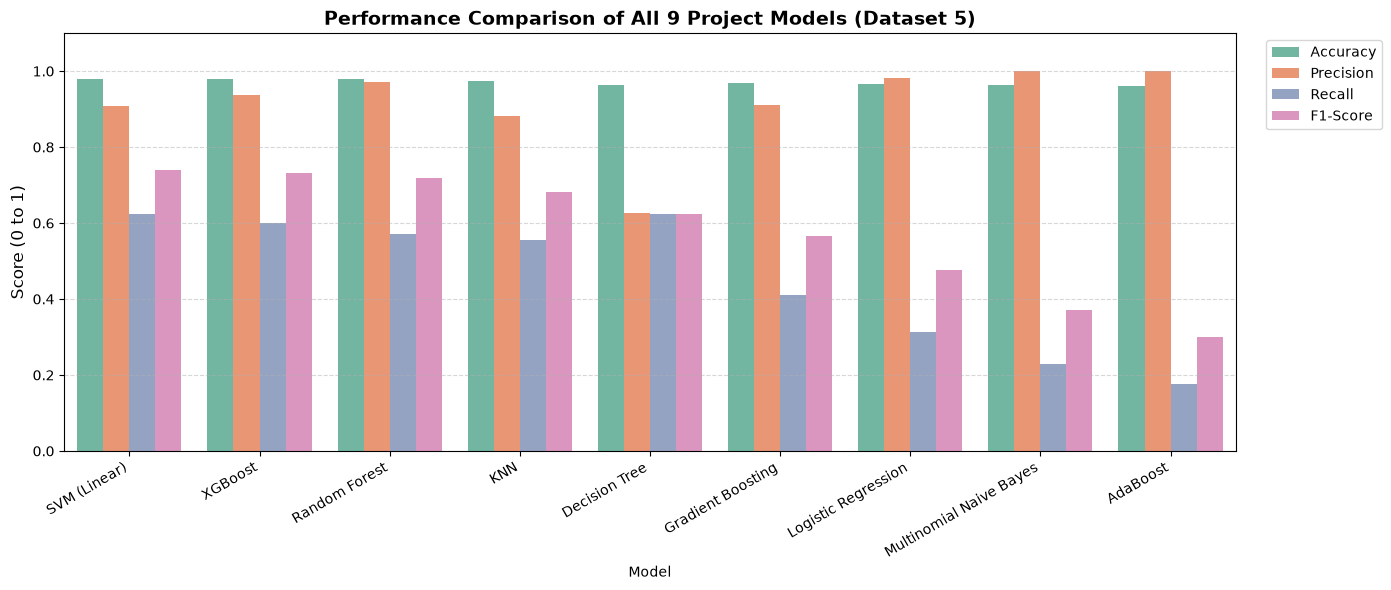

 Best Performing Model on Dataset 5 is: SVM (Linear)


In [25]:
# Comparison Summary Table
comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n--- Dataset 5: 9 Models Performance Comparison ---")
display(comparison_df)

# Save the TF-IDF Vectorizer
joblib.dump(tfidf, "saved_models/tfidf_vectorizer_dataset5.pkl")

# Comparison Bar Chart
plt.figure(figsize=(14, 6))
df_melted = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Performance Comparison of All 9 Project Models (Dataset 5)", fontsize=14, fontweight='bold')
plt.ylabel("Score (0 to 1)", fontsize=12)
plt.ylim(0.0, 1.1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("saved_models/dataset5_model_comparison.png", dpi=300)
plt.show()

# Print Top Performer
best_model_name = comparison_df.iloc[0]["Model"]
print(f" Best Performing Model on Dataset 5 is: {best_model_name}")

## Final Model For Dataset5 = SVM